# Variational inference for a Gaussian mixture

**Gabriel Trabelsi**

Coordinate-ascent variational inference (CAVI) for a Bayesian mixture of Gaussians, following the example of Blei, Kucukelbir and McAuliffe, *Variational Inference: A Review for Statisticians* (2017), then a comparison of the variational posterior with a Metropolis sampler.

**Academic context:** supplied TP8 practical (variational inference) from the same Statistique Computationnelle course as the MCMC and EM notebooks, Sorbonne Université, Master 1, 2025-2026. The supplied header gives no individual instructor attribution. Function signatures and docstrings come from the exercise framework; the implementations and experiments are by Gabriel Trabelsi.

**About the outputs:** the original notebook was run without a fixed seed and its cells were not executed in order. The selected cells were therefore re-executed in order, in a fresh kernel on 16 October 2026, with the seed cell added below. Two leftover debugging lines and template comments were removed; the algorithms are unchanged. Working notes and exercise prompts are not included.

In [ ]:
"""""""""""""""""
Required packages
"""""""""""""""""
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

In [ ]:
from numpy.random import default_rng
rng = default_rng()
#rng = default_rng(10) # si on veut tous les mêmes simulations

In [ ]:
rng = default_rng(0)  # Added for this presentation run; the original notebook used no fixed seed.
np.random.seed(0)

## 1. Model and simulated data

$K$ unit-variance Gaussian components with means $\mu_k \sim \mathcal N(0,\sigma^2)$, independent assignments $c_i$ uniform on $\{1,\ldots,K\}$, and $X_i \mid (\mu, c) \sim \mathcal N(\mu_{c_i}, 1)$. The data below use $K=3$, $\sigma^2=5$ and $n=1000$.

In [ ]:
K = 3
mu = rng.normal(loc=0, scale=np.sqrt(5), size=K)
n_samples = 1000
c = np.random.choice(K, n_samples, p=np.ones(K)/K)  # indices dans {0,1,2}
sample = rng.normal(loc=mu[c], scale=1)              # vectorisé, plus efficace

## 2. Mean-field family and CAVI updates

The posterior $p(\mu, c \mid x)$ is approximated by $q(\mu,c)=\prod_k \mathcal N(\mu_k; m_k, s_k^2)\prod_i \mathrm{Cat}(c_i;\phi_i)$. Coordinate ascent alternates the closed-form updates

$$\phi_{ik} \propto \exp\!\Big(m_k x_i - \tfrac{m_k^2 + s_k^2}{2}\Big), \qquad s_k^2 = \Big(\tfrac{1}{\sigma^2} + \sum_i \phi_{ik}\Big)^{-1}, \qquad m_k = s_k^2 \sum_i \phi_{ik}\, x_i .$$

In the code, `s2` holds the variances $s_k^2$.

In [ ]:
def CAVI_update_phi(X,m,s2):
    """
    Inputs
    ----------
    X: data
    m: current estimation of the m_k
    s2: current estimation of the s_k
    
    Outputs
    -------
    phi: new estimation of phi
    """
    K = len(m)
    
    phi = np.outer(m, X)
    phi = np.exp(phi - (m**2+s2)[:, None]/2)
    phi = phi/phi.sum(axis=0) 
    
    return phi

In [ ]:
def CAVI_update_mu_s2(X,m,phi,s2,sigma2):
    """
    Inputs
    ----------
    X: data
    m: current estimation of the m_k
    s2: current estimation of the s_k
    phi: current estimation of phi
    sigma2: current estimation of sigma^2
    
    Outputs
    -------
    m, s2: new estimation of the m_k and the s_k
    """
    s2 = phi.sum(axis=1) + 1/sigma2
    s2 = 1/s2

    m = (phi*X).sum(axis=1) * s2

    return m, s2

## 3. Evidence lower bound

Up to additive constants, the ELBO is

$$-\sum_k \frac{m_k^2+s_k^2}{2\sigma^2} \;-\; \frac12\sum_{i,k}\phi_{ik}\big[(x_i-m_k)^2+s_k^2\big] \;+\; \frac12\sum_k \log s_k^2 \;-\; \sum_{i,k}\phi_{ik}\log\phi_{ik}.$$

In [ ]:

def elbo(X,phi,m,s2,sigma2):
    """
    Inputs
    ----------
    X: data
    m: current estimation of the m_k
    s2: current estimation of the s_k
    phi: current estimation of phi
    sigma2: current estimation of sigma^2
    
    Outputs
    -------
    elbo: value of the elbo with the input parameters
    """
    A = -(m**2+s2).sum() * 1/(2*sigma2)
    B = -1/2 * (((X[None, :]-m[:, None])**2)+s2[:, None])*phi
    B = B.sum()
    C = 1/2*np.log(s2).sum()
    D = -(phi * np.log(phi)).sum()

    return A + B + C + D

## 4. CAVI loop

The updates are iterated until the ELBO changes by less than $10^{-8}$, or for at most 500 iterations.

In [ ]:
def CAVI_mixture_Gaussian(X,m, s2, phi, sigma2, max_iter = 500, epsilon = 1e-8):
    """
    Inputs
    ----------
    X: data
    m: initial estimation of the m_k
    s2: initial estimation of the s_k
    phi: initial estimation of phi
    sigma2: initial estimation of sigma^2
    
    Outputs
    -------
    elbos: value of the elbo long iterations
    m_est, s2_est: sequence of estimators along iterations

    """

    m_est = []
    s2_est = []
    elbos = []

    n = len(X)

    for i in range(max_iter):
        phi = CAVI_update_phi(X, m, s2)
        m, s2 = CAVI_update_mu_s2(X,m,phi, s2, sigma2)
        elbos.append(elbo(X, phi, m, s2, sigma2))

        m_est.append(m); s2_est.append(s2)
        if i > 0 and abs(elbos[-1] - elbos[-2]) < epsilon:
            break
    

    
    return np.array(elbos), np.array(m_est), np.array(s2_est)

## 5. One run, then ten random initialisations

ELBO and mean estimates along the iterations (dashed lines: true means), then the final ELBO and means for ten random initialisations.

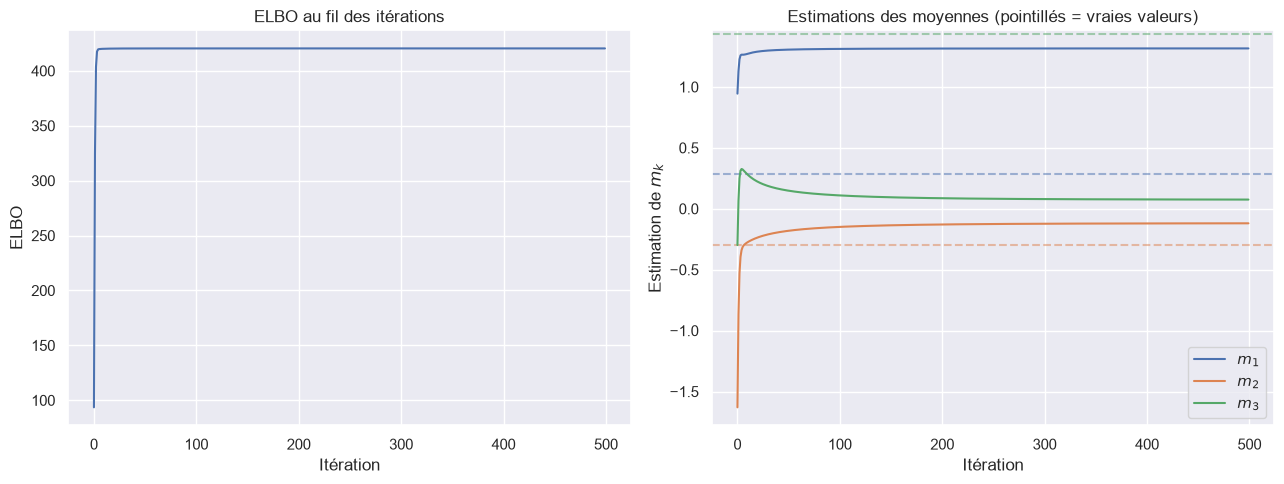

In [ ]:
# Initialisation
sigma2 = 5
m_init = rng.normal(0, np.sqrt(sigma2), size=K)
s2_init = np.ones(K)
phi_init = rng.dirichlet(np.ones(K), size=n_samples).T  # (K, n)

# Conversion en array si besoin
X = np.array(sample).flatten()

# Lancer CAVI
elbos, m_est, s2_est = CAVI_mixture_Gaussian(X, m_init, s2_init, phi_init, sigma2)

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ELBO
axes[0].plot(elbos)
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("ELBO")
axes[0].set_title("ELBO au fil des itérations")

# Paramètres m_k
m_est = np.array(m_est)  # shape (n_iter, K)
for k in range(K):
    axes[1].plot(m_est[:, k], label=f"$m_{k+1}$")
    axes[1].axhline(mu[k], color=f"C{k}", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Itération")
axes[1].set_ylabel("Estimation de $m_k$")
axes[1].set_title("Estimations des moyennes (pointillés = vraies valeurs)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation.** The ELBO reaches its plateau within about ten iterations, but two of the means keep drifting for about a hundred more, so the $10^{-8}$ stopping threshold is never met and the loop stops at 500 iterations. The isolated component (true mean 1.43) is estimated at 1.32. The two other components overlap strongly (true means $-0.30$ and $0.28$, with unit variance), and their estimates, $-0.12$ and $0.08$, are pulled towards each other.

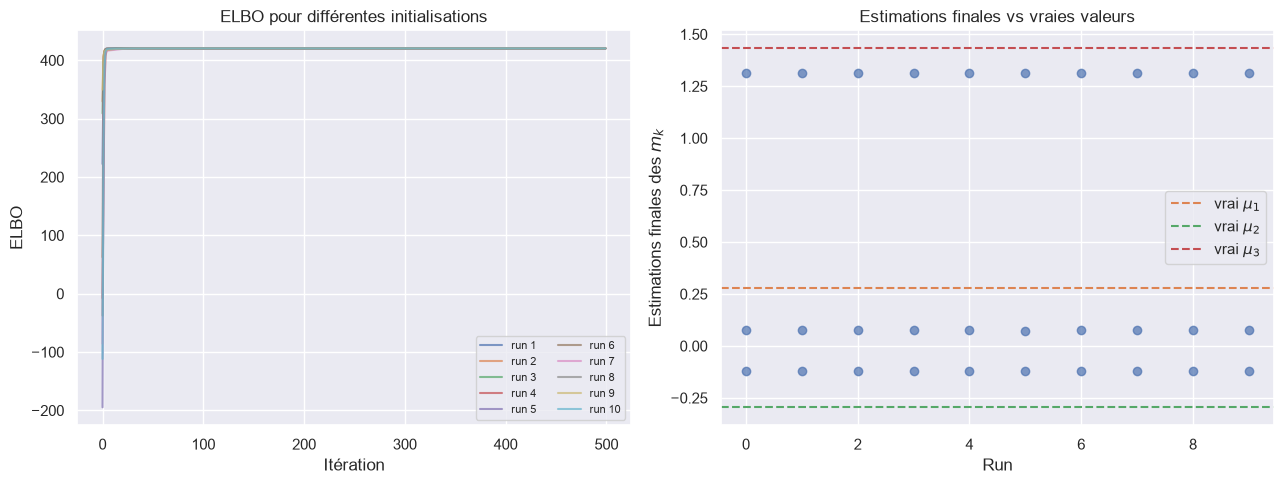

ELBO finales :
  Run 1: ELBO = 420.392, m = [-0.12   0.075  1.316]
  Run 2: ELBO = 420.392, m = [-0.12   0.075  1.316]
  Run 3: ELBO = 420.392, m = [-0.12   0.075  1.316]
  Run 4: ELBO = 420.392, m = [-0.12   0.075  1.316]
  Run 5: ELBO = 420.392, m = [-0.12   0.075  1.316]
  Run 6: ELBO = 420.392, m = [-0.118  0.074  1.316]
  Run 7: ELBO = 420.392, m = [-0.12   0.075  1.316]
  Run 8: ELBO = 420.392, m = [-0.119  0.075  1.316]
  Run 9: ELBO = 420.392, m = [-0.12   0.075  1.316]
  Run 10: ELBO = 420.392, m = [-0.12   0.075  1.316]


In [ ]:
n_runs = 10
results = []

for run in range(n_runs):
    # Nouvelle initialisation aléatoire à chaque run
    m_init = rng.normal(0, np.sqrt(sigma2), size=K)
    s2_init = np.ones(K)
    phi_init = rng.dirichlet(np.ones(K), size=n_samples).T
    
    elbos, m_est, s2_est = CAVI_mixture_Gaussian(X, m_init, s2_init, phi_init, sigma2)
    results.append({
        "elbos": elbos,
        "m_est": np.array(m_est),
        "m_init": m_init,
        "final_elbo": elbos[-1],
        "final_m": np.array(m_est)[-1],
    })

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ELBO pour chaque run
for i, res in enumerate(results):
    axes[0].plot(res["elbos"], alpha=0.7, label=f"run {i+1}")
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("ELBO")
axes[0].set_title("ELBO pour différentes initialisations")
axes[0].legend(fontsize=8, ncol=2)

# Estimations finales des m_k vs vraies valeurs
for i, res in enumerate(results):
    axes[1].scatter([i]*K, res["final_m"], color="C0", alpha=0.7)
for k in range(K):
    axes[1].axhline(mu[k], color=f"C{k+1}", linestyle="--", 
                    label=f"vrai $\\mu_{k+1}$")
axes[1].set_xlabel("Run")
axes[1].set_ylabel("Estimations finales des $m_k$")
axes[1].set_title("Estimations finales vs vraies valeurs")
axes[1].legend()

plt.tight_layout()
plt.show()

# Résumé numérique
print("ELBO finales :")
for i, res in enumerate(results):
    print(f"  Run {i+1}: ELBO = {res['final_elbo']:.3f}, "
          f"m = {np.sort(res['final_m']).round(3)}")

**Observation.** All ten random initialisations reach the same ELBO (420.392) and the same means, up to the order of the components: on this data set, CAVI is not sensitive to its starting point.

## 6. Comparison with MCMC

To check the quality of $q$, the marginal posterior $p(\mu \mid x)$, with the assignments summed out, is sampled by random-walk Metropolis (30,000 iterations, 5,000 discarded as burn-in). The chain starts at the CAVI solution to avoid label switching. Each marginal $q(\mu_k)$ is compared with the MCMC histogram.

Taux d'acceptation MH : 66.67%


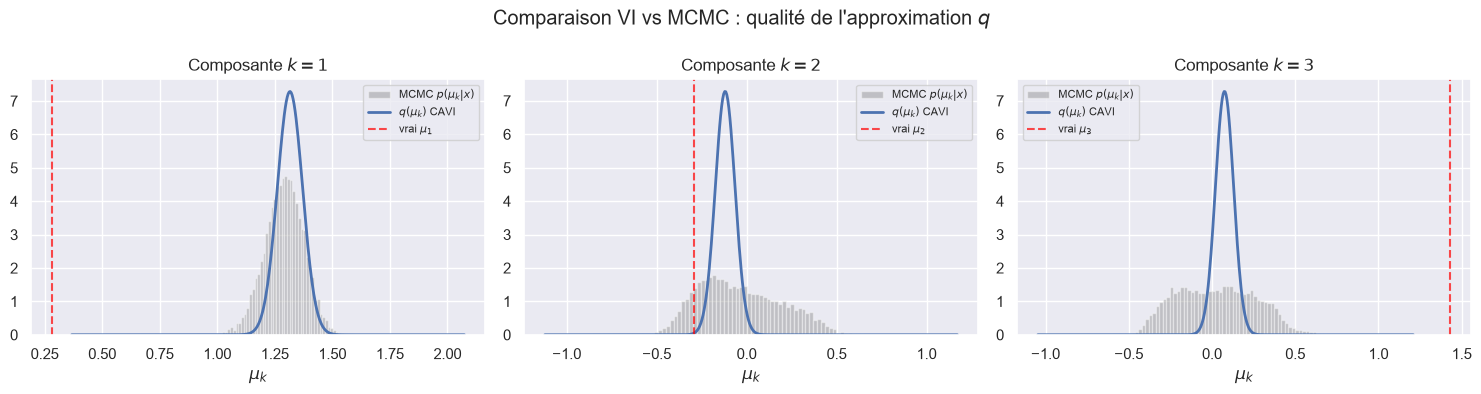


Comparaison numérique :
k    m_k (CAVI)     mean MCMC      sqrt(s2_k) CAVI     std MCMC       
1    1.3157         1.2891         0.0547              0.0852         
2    -0.1195        -0.0364        0.0548              0.2305         
3    0.0752         0.0257         0.0548              0.2361         


In [ ]:
from scipy.special import logsumexp

# 1. Log-posterior marginalisé sur c (forme close)
#    log p(mu|x) ∝ log p(mu) + sum_i log( (1/K) sum_k N(x_i|mu_k, 1) )
def log_posterior(mu, X, sigma2):
    K = len(mu)
    log_prior = -np.sum(mu**2) / (2 * sigma2)
    # log p(x_i | mu) pour chaque i et chaque k
    diff = X[:, None] - mu[None, :]                  # (n, K)
    log_comp = -0.5 * diff**2 - 0.5*np.log(2*np.pi)  # (n, K)
    log_lik = np.sum(logsumexp(log_comp, axis=1) - np.log(K))
    return log_prior + log_lik


# 2. Metropolis-Hastings avec marche aléatoire gaussienne
def metropolis_hastings(X, sigma2, K, n_iter=30000, step=0.15, init=None):
    mu = np.zeros(K) if init is None else init.copy()
    samples = np.zeros((n_iter, K))
    log_p = log_posterior(mu, X, sigma2)
    accepted = 0
    for t in range(n_iter):
        proposal = mu + rng.normal(0, step, size=K)
        log_p_new = log_posterior(proposal, X, sigma2)
        if np.log(rng.uniform()) < log_p_new - log_p:
            mu, log_p = proposal, log_p_new
            accepted += 1
        samples[t] = mu
    print(f"Taux d'acceptation MH : {accepted/n_iter:.2%}")
    return samples


# 3. Lancer MCMC en initialisant proche de la solution CAVI
#    (évite le label switching pendant le burn-in)
m_final = m_est[-1]
s2_final = s2_est[-1]

mcmc_samples = metropolis_hastings(X, sigma2, K,
                                    n_iter=30000, step=0.05,
                                    init=m_final)

# Burn-in
burn = 5000
mcmc_samples = mcmc_samples[burn:]


# 4. Comparaison q(mu_k) vs marginale MCMC de p(mu_k|x)
fig, axes = plt.subplots(1, K, figsize=(15, 4))

for k in range(K):
    ax = axes[k]
    
    # Histogramme MCMC = approximation de p(mu_k|x)
    ax.hist(mcmc_samples[:, k], bins=60, density=True,
            alpha=0.4, color="gray", label="MCMC $p(\\mu_k|x)$")
    
    # Densité variationnelle q(mu_k) = N(m_k, s2_k)
    grid = np.linspace(mcmc_samples[:, k].min()-0.5,
                       mcmc_samples[:, k].max()+0.5, 400)
    q_density = (1/np.sqrt(2*np.pi*s2_final[k])) * \
                np.exp(-(grid - m_final[k])**2 / (2*s2_final[k]))
    ax.plot(grid, q_density, "C0", lw=2, label="$q(\\mu_k)$ CAVI")
    
    # Vraie valeur génératrice
    ax.axvline(mu[k], color="red", linestyle="--", alpha=0.7,
               label=f"vrai $\\mu_{k+1}$")
    
    ax.set_title(f"Composante $k={k+1}$")
    ax.set_xlabel("$\\mu_k$")
    ax.legend(fontsize=8)

plt.suptitle("Comparaison VI vs MCMC : qualité de l'approximation $q$")
plt.tight_layout()
plt.show()


# 5. Comparaison numérique : moyennes et écart-types
print("\nComparaison numérique :")
print(f"{'k':<5}{'m_k (CAVI)':<15}{'mean MCMC':<15}{'sqrt(s2_k) CAVI':<20}{'std MCMC':<15}")
for k in range(K):
    print(f"{k+1:<5}{m_final[k]:<15.4f}"
          f"{mcmc_samples[:, k].mean():<15.4f}"
          f"{np.sqrt(s2_final[k]):<20.4f}"
          f"{mcmc_samples[:, k].std():<15.4f}")

**Observation.** The two methods agree on the location of the isolated component (posterior mean 1.32 for CAVI, 1.29 for MCMC) but not on its uncertainty: the variational standard deviation is 0.055, against 0.085 for MCMC. This is the known tendency of mean-field VI to underestimate posterior variance. The gap is much larger for the two overlapping components: their MCMC marginals are about four times wider (s.d. $\approx 0.23$) and cover both true values, partly because the chain can swap these two nearly interchangeable labels, whereas $q$ stays concentrated on a single configuration. The variational point estimates are useful; its uncertainty, taken at face value, would be over-confident.

## Limits

A single simulated data set, with $K$ and the unit component variance known. The Metropolis reference is one chain started at the CAVI solution, without multi-chain convergence diagnostics or effective-sample-size estimates. The ELBO is computed up to additive constants.